# DAY 5

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt


vader = pd.read_csv("results_vader.csv")
nb = pd.read_csv("results_nb.csv")
llm = pd.read_csv("results_llm.csv")

results = pd.concat([vader, nb, llm], ignore_index=True)   # stack the three rows into one table
results.to_csv("results_table.csv", index=False)
print(results)

                Model  Accuracy  Macro-F1  Hard cases acc.  Sec per 1k preds  \
0               VADER     0.707     0.683            0.667             2.489   
1  NLTK + Naive Bayes     0.853     0.853            0.667             0.269   
2       LLM zero-shot     0.960     0.976            0.933           783.400   

   Cost per 1k preds  
0             0.0000  
1             0.0000  
2             0.0282  


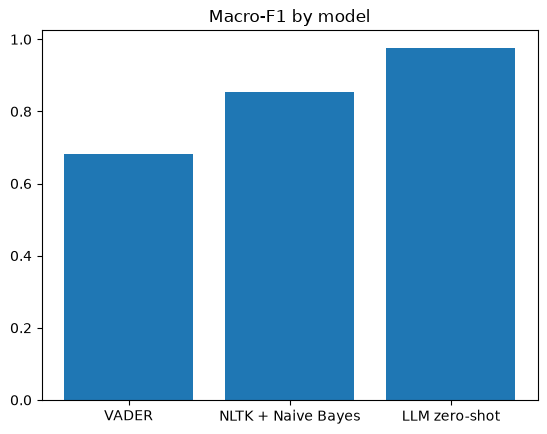

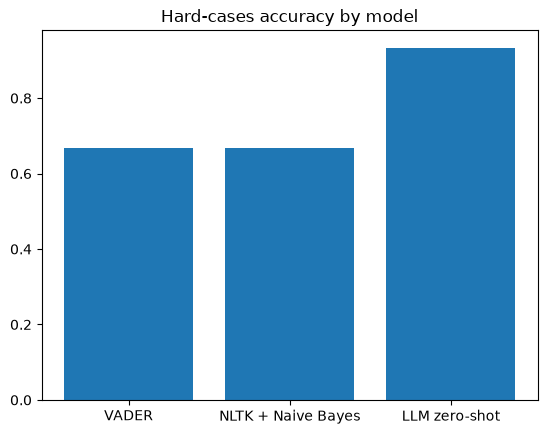

In [7]:
plt.bar(results["Model"], results["Macro-F1"])
plt.title("Macro-F1 by model")
plt.savefig("chart_macro_f1.png")
plt.show()

plt.bar(results["Model"], results["Hard cases acc."])
plt.title("Hard-cases accuracy by model")
plt.savefig("chart_hard_cases.png")
plt.show()

In [8]:
pd.set_option("display.max_colwidth", 200)       # show more of each review

# --- VADER's mistakes ---
vader_preds = pd.read_csv("test_300_with_vader.csv")
vader_wrong = vader_preds[vader_preds["y"] != vader_preds["vader_pred"]]

print("VADER got", len(vader_wrong), "wrong out of 300")
print(vader_wrong[["y", "vader_pred", "text"]].head(8))

VADER got 88 wrong out of 300
           y vader_pred  \
0   negative   positive   
1   negative   positive   
2   negative   positive   
5   negative   positive   
11  negative   positive   
12  negative   positive   
14  negative   positive   
15  negative   positive   

                                                                                                                                                                                                       text  
0   I bought the buffet all day pass m decided to try out this place. Not one of the best buffets that I have been to. I love seafood but I'm not sure what the buzz was about the crab legs. For the pr...  
1   I don't even know where to begin. Archi's has never failed me before, but this was my first time at this location. My family took Dan T. and I here for a Sunday afternoon lunch. My parents were ig...  
2   The food was actually great, this review is for the service. \nI was actually blown away by the terrible

In [9]:
# --- Naive Bayes mistakes ---
nb_preds = pd.read_csv("test_300_with_nb.csv")
nb_wrong = nb_preds[nb_preds["y"] != nb_preds["nb_pred"]]

print("Naive Bayes got", len(nb_wrong), "wrong out of 300")
print(nb_wrong[["y", "nb_pred", "text"]].head(8))

# --- LLM mistakes ---
llm_preds = pd.read_csv("test_300_with_llm.csv")
llm_wrong = llm_preds[llm_preds["y"] != llm_preds["llm_pred"]]

print("LLM got", len(llm_wrong), "wrong out of 300")
print(llm_wrong[["y", "llm_pred", "text"]].head(8))

Naive Bayes got 44 wrong out of 300
           y   nb_pred  \
0   negative  positive   
9   positive  negative   
20  positive  negative   
35  negative  positive   
37  positive  negative   
54  positive  negative   
61  negative  positive   
69  negative  positive   

                                                                                                                                                                                                       text  
0   I bought the buffet all day pass m decided to try out this place. Not one of the best buffets that I have been to. I love seafood but I'm not sure what the buzz was about the crab legs. For the pr...  
9   Always make a 7 AM appointment (for fasting tests) and usually get called in within 5 minutes of appointment time. Consistently good. We always go to the location at Lake Mead and Buffalo. Staff i...  
20  Dined here last night. The food was very good indeed (lamb kurma, chicken saag, and a few other dishes), we

In [10]:
print([f for f in os.listdir(".") if f.endswith(".csv")])

['hard_cases.csv', 'hard_cases_with_nb.csv', 'hard_cases_with_vader.csv', 'results_llm.csv', 'results_nb.csv', 'results_table.csv', 'results_vader.csv', 'test.csv', 'test_300.csv', 'test_300_with_llm.csv', 'test_300_with_nb.csv', 'test_300_with_vader.csv', 'train.csv']


In [11]:
hard_vader = pd.read_csv("hard_cases_with_vader.csv")
print(hard_vader[hard_vader["y"] != hard_vader["vader_pred"]][["text", "y", "vader_pred"]])

                                                              text         y  \
1                 Oh great, another hour-long wait for cold fries.  negative   
3                             I wouldn’t say the service was good.  negative   
6                    Wow, I love paying $30 for a lukewarm burger.  negative   
8                          The steak was alright but I had better.  negative   
10                                  I wish the service was better.  negative   
12                 The preparation time for the food took a while.  negative   
20                    The atmosphere didn't match the food at all.  negative   
21  They didn't provide any options for milder flavors of noodles.  negative   
22           The pasta came out a little overcooked in my opinion.  negative   
23       The seafood selection didn't have a non-shellfish option.  negative   

   vader_pred  
1    positive  
3    positive  
6    positive  
8    positive  
10   positive  
12   positive  
20   po